# Visualiser les données EEG avant le décodage

**But :** comprendre ce que le classifieur reçoit en entrée, avant d'entraîner quoi que ce soit.

1. Charger un sujet et regarder la structure des essais
2. D'où viennent les 120 et les 360 essais
3. Un essai brut : à quoi ressemble le signal EEG
4. Moyenner les essais : le potentiel évoqué (ERP)
5. Sain vs pas sain : y a-t-il une différence visible ?
6. Ce que voit le classifieur à un instant donné

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

DATA_FILE = "/Users/firyalelalj/Library/CloudStorage/GoogleDrive-firyal.elalj@epfl.ch/Mon Drive/epoch_data_6sujets.nc"
SUJET = "sub-006_task-categorisation"

ds = xr.open_dataset(DATA_FILE)              # lecture paresseuse : rien n'est chargé
s = ds.sel(recording=SUJET).load()           # on ne charge qu'un sujet (~130 Mo)
SFREQ = float(ds.attrs["sfreq"])             # 256 Hz
temps_ms = s.sample.values / SFREQ * 1000    # -250 ms ... 2500 ms
canaux = list(s.channel.values)
print(s["data"].shape, "= (epochs, électrodes, points de temps)")

(721, 64, 705) = (epochs, électrodes, points de temps)


## 1. Structure des essais

Chaque ligne = une **epoch** (un morceau de signal découpé autour d'un événement). Chaque essai est découpé deux fois :
- `display` : autour de l'apparition de l'**image** (le participant regarde, il ne connaît pas encore la question)
- `choice` : autour de l'apparition de la **question** (Healthy? / Tasty? / Like to eat?)

In [2]:
cols = ["event_name", "event_type", "food_image_code", "resp_choice", "resp_position", "choice_rt"]
meta = pd.DataFrame({c: s[c].values for c in cols})
meta.head(10)

,event_name,event_type,food_image_code,resp_choice,resp_position,choice_rt
0,display,taste,foodImage.46,Yes,Right,1.078362
1,choice,taste,foodImage.46,Yes,Right,1.078362
2,display,health,foodImage.49,Yes,Right,0.903852
3,choice,health,foodImage.49,Yes,Right,0.903852
4,display,decision,foodImage.114,No,Left,0.912746
5,choice,decision,foodImage.114,No,Left,0.912746
6,display,taste,foodImage.54,Yes,Right,0.850428
7,choice,taste,foodImage.54,Yes,Right,0.850428
8,display,health,foodImage.98,Yes,Right,2.342983
9,choice,health,foodImage.98,Yes,Right,2.342983


In [3]:
print(meta.event_name.value_counts(), "\n")
print(pd.crosstab(meta.event_name, meta.event_type))

event_name
display    360
choice     360
             1
Name: count, dtype: int64 

event_type     decision  health  taste
event_name                            
            1         0       0      0
choice      0       120     120    120
display     0       120     120    120


## 2. D'où viennent les 120 et les 360 essais

On garde seulement les epochs `display` (le participant regarde l'image) → **360 essais** = 120 images × 3 présentations.
Chaque image est vue 3 fois, et après chaque présentation une question différente est posée :

In [4]:
display = s.event_name.values == "display"
eeg = s["data"].values[display] * 1e6        # volts -> microvolts, forme (360, 64, 705)
question = s.event_type.values[display]
reponse = s.resp_choice.values[display]
image = s.food_image_code.values[display]

essais = pd.DataFrame({"image": image, "question": question, "reponse": reponse})
exemple = image[0]
essais[essais.image == exemple]

,image,question,reponse
0,foodImage.46,taste,Yes
23,foodImage.46,health,Yes
234,foodImage.46,decision,Yes


**Version 120 essais (notebook de Rafaela)** : on ne garde que les essais où la question était *Healthy?*. Là, « Yes » veut dire « sain ».

**Version 360 essais (`outils.py`)** : pendant les 2 s d'image, le participant **ne sait pas encore quelle question viendra** (l'ordre est aléatoire). Son cerveau traite donc la même image de la même façon dans les 3 essais. On prend la réponse *Healthy?* de cette image et on la **recopie** sur ses 2 autres essais.

→ 3× plus de données, mais les étiquettes ne sont pas indépendantes : les 3 essais d'une image ont la même étiquette. Il faut donc que les 3 essais d'une image soient **tous** dans le train ou **tous** dans le test (`StratifiedGroupKFold` avec `groups=image`). Sinon le classifieur peut « reconnaître l'image » vue à l'entraînement au lieu d'apprendre la notion sain / pas sain.

In [5]:
health = question == "health"
etiquette_image = dict(zip(image[health], reponse[health] == "Yes"))   # image -> sain ?

y120 = (reponse[health] == "Yes").astype(int)                   # 120 étiquettes
y360 = np.array([etiquette_image[i] for i in image]).astype(int)  # 360 étiquettes (recopiées)

print("120 essais :", np.bincount(y120), "(pas sain, sain)")
print("360 essais :", np.bincount(y360), "(pas sain, sain)")

120 essais : [62 58] (pas sain, sain)
360 essais : [186 174] (pas sain, sain)


## 3. Un essai brut

Les données sont **directement le signal EEG** : la tension (en µV) mesurée sur chacune des 64 électrodes, 256 fois par seconde. Déjà prétraité : filtré 0,5–40 Hz, référence moyenne, nettoyé (GEDAI), ligne de base −250→0 ms soustraite.

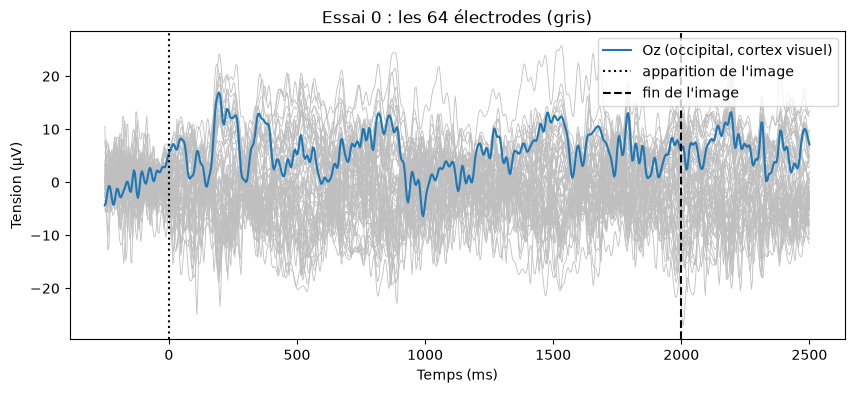

In [6]:
essai = 0
oz = canaux.index("Oz")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(temps_ms, eeg[essai].T, color="0.75", linewidth=0.6)
ax.plot(temps_ms, eeg[essai, oz], color="tab:blue", linewidth=1.5, label="Oz (occipital, cortex visuel)")
ax.axvline(0, color="k", linestyle=":", label="apparition de l'image")
ax.axvline(2000, color="k", linestyle="--", label="fin de l'image")
ax.set(xlabel="Temps (ms)", ylabel="Tension (µV)", title=f"Essai {essai} : les 64 électrodes (gris)")
ax.legend(loc="upper right")
plt.show()

Sur un seul essai, le signal est surtout du **bruit** : la réponse à l'image est noyée dans l'activité de fond. Comparons plusieurs essais sur la même électrode :

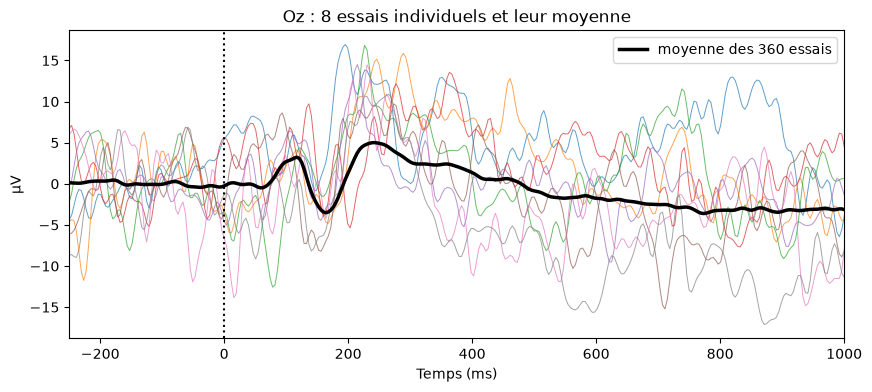

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
for i in range(8):
    ax.plot(temps_ms, eeg[i, oz], linewidth=0.7, alpha=0.7)
ax.plot(temps_ms, eeg[:, oz].mean(axis=0), color="k", linewidth=2.5, label="moyenne des 360 essais")
ax.axvline(0, color="k", linestyle=":")
ax.set(xlim=(-250, 1000), xlabel="Temps (ms)", ylabel="µV", title="Oz : 8 essais individuels et leur moyenne")
ax.legend()
plt.show()

## 4. Moyenner : le potentiel évoqué (ERP)

Quand on moyenne beaucoup d'essais, le bruit (aléatoire) s'annule et la réponse cérébrale à l'image (toujours au même moment) apparaît : c'est l'**ERP**. On voit les pics visuels classiques P1 (~100 ms), N1 (~170 ms), P2 (~250 ms).

Image ci-dessous : chaque ligne = un essai sur Oz, couleur = tension. Les bandes verticales sont la réponse à l'image, cohérente d'un essai à l'autre.

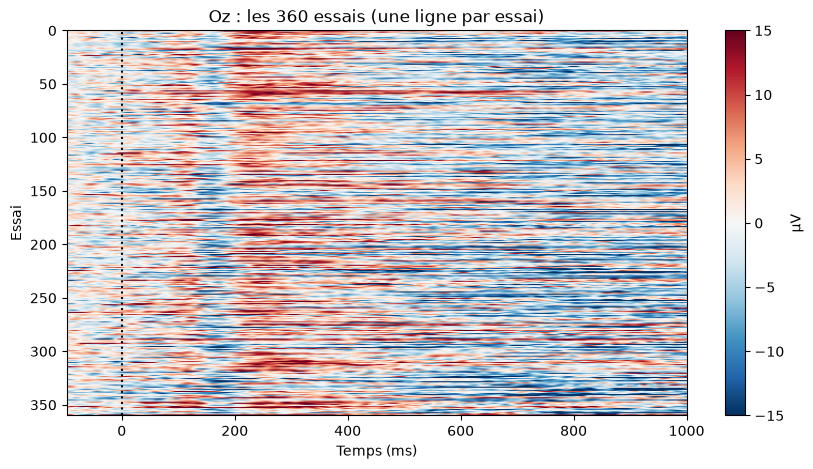

In [8]:
fenetre = (temps_ms >= -100) & (temps_ms <= 1000)
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(eeg[:, oz, fenetre], aspect="auto", cmap="RdBu_r", vmin=-15, vmax=15,
               extent=[temps_ms[fenetre][0], temps_ms[fenetre][-1], len(eeg), 0])
ax.axvline(0, color="k", linestyle=":")
ax.set(xlabel="Temps (ms)", ylabel="Essai", title="Oz : les 360 essais (une ligne par essai)")
fig.colorbar(im, label="µV")
plt.show()

## 5. Sain vs pas sain : une différence visible ?

Comme dans la Figure 2 de l'article : on moyenne séparément les essais « sain » et « pas sain », sur deux groupes d'électrodes. Zone grisée = erreur standard. L'article trouve une différence vers **150–600 ms** sur les électrodes occipitales (avec ~110 sujets).

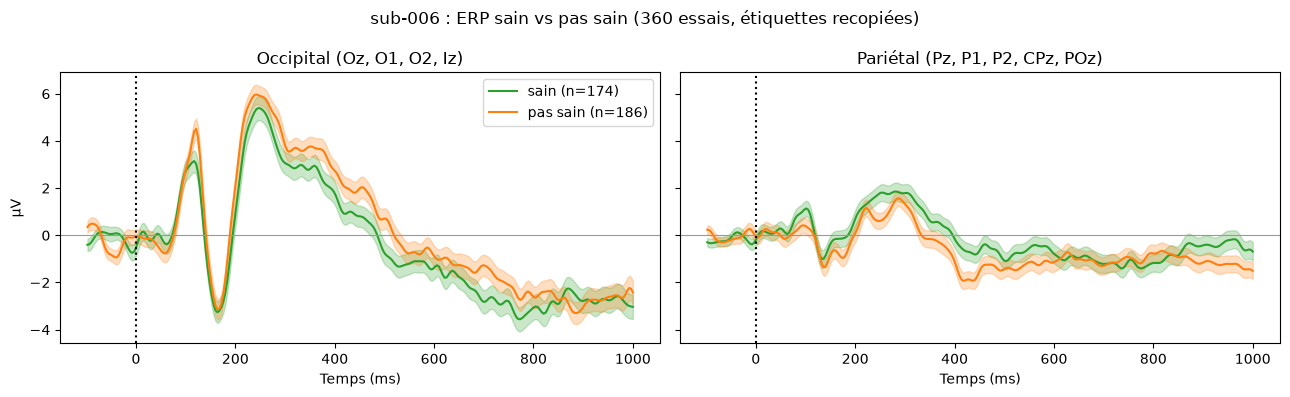

In [9]:
regions = {"Occipital (Oz, O1, O2, Iz)": ["Oz", "O1", "O2", "Iz"],
           "Pariétal (Pz, P1, P2, CPz, POz)": ["Pz", "P1", "P2", "CPz", "POz"]}

def erp(x):
    return x.mean(axis=0), x.std(axis=0) / np.sqrt(len(x))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (nom, elecs) in zip(axes, regions.items()):
    idx = [canaux.index(e) for e in elecs]
    signal = eeg[:, idx][:, :, fenetre].mean(axis=1)          # moyenne des électrodes -> (360, temps)
    for classe, couleur, label in [(1, "tab:green", "sain"), (0, "tab:orange", "pas sain")]:
        m, se = erp(signal[y360 == classe])
        ax.plot(temps_ms[fenetre], m, color=couleur, label=f"{label} (n={np.sum(y360 == classe)})")
        ax.fill_between(temps_ms[fenetre], m - se, m + se, color=couleur, alpha=0.25)
    ax.axvline(0, color="k", linestyle=":")
    ax.axhline(0, color="0.6", linewidth=0.8)
    ax.set(title=nom, xlabel="Temps (ms)")
axes[0].set_ylabel("µV")
axes[0].legend()
fig.suptitle(f"{SUJET[:7]} : ERP sain vs pas sain (360 essais, étiquettes recopiées)")
plt.tight_layout()
plt.show()

Et sur **toutes** les électrodes : différence (sain − pas sain) pour chaque électrode et chaque instant. Rouge = plus positif pour « sain », bleu = plus négatif.

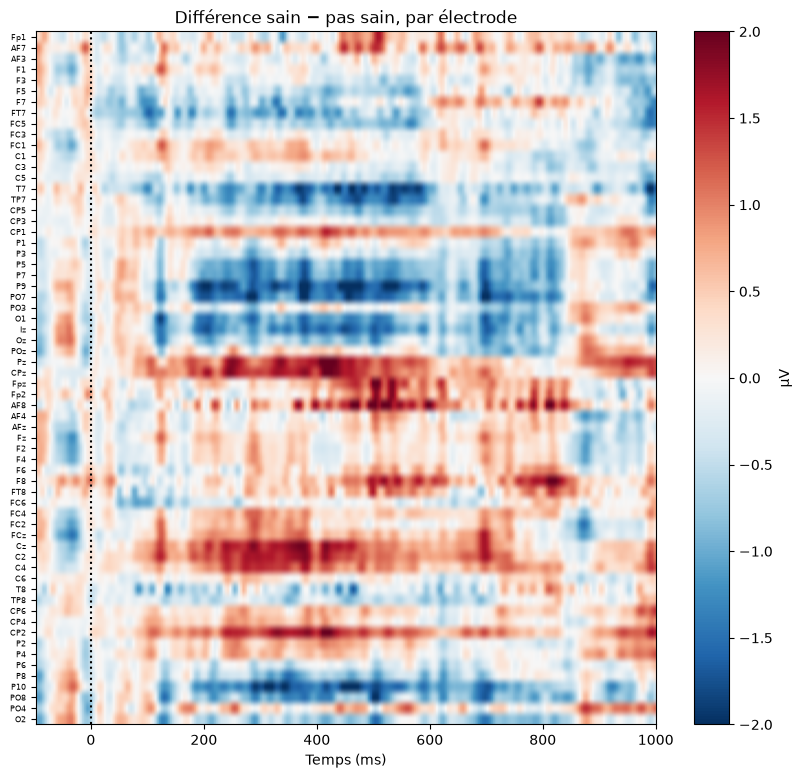

In [10]:
diff = eeg[y360 == 1].mean(axis=0) - eeg[y360 == 0].mean(axis=0)     # (64, temps)
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(diff[:, fenetre], aspect="auto", cmap="RdBu_r", vmin=-2, vmax=2,
               extent=[temps_ms[fenetre][0], temps_ms[fenetre][-1], 64, 0])
ax.set_yticks(np.arange(64) + 0.5)
ax.set_yticklabels(canaux, fontsize=6)
ax.axvline(0, color="k", linestyle=":")
ax.set(xlabel="Temps (ms)", title="Différence sain − pas sain, par électrode")
fig.colorbar(im, label="µV")
plt.show()

## 6. Ce que voit le classifieur

Dans le décodage « au cours du temps », on entraîne **un classifieur par instant t**. À l'instant t, chaque essai est décrit par **64 nombres** : la tension de chaque électrode à cet instant. C'est la matrice `X[:, :, t]` de forme (360, 64) :
- une ligne = un essai
- une colonne = une électrode
- l'étiquette y = sain (1) ou pas sain (0)

La régression logistique cherche une combinaison des 64 électrodes qui sépare les deux classes. Ci-dessous à t = 400 ms, essais triés par classe.

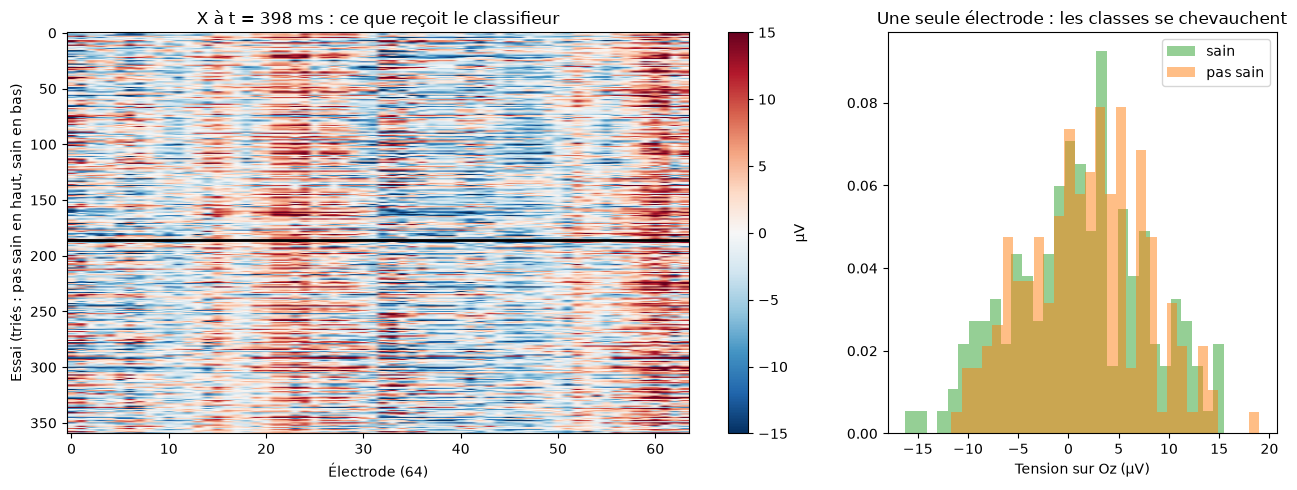

In [11]:
t = np.argmin(np.abs(temps_ms - 400))
X_t = eeg[:, :, t]                         # (360, 64)
ordre = np.argsort(y360)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2, 1]})
im = ax1.imshow(X_t[ordre], aspect="auto", cmap="RdBu_r", vmin=-15, vmax=15)
ax1.axhline(np.sum(y360 == 0) - 0.5, color="k", linewidth=2)
ax1.set(xlabel="Électrode (64)", ylabel="Essai (triés : pas sain en haut, sain en bas)",
        title=f"X à t = {temps_ms[t]:.0f} ms : ce que reçoit le classifieur")
fig.colorbar(im, ax=ax1, label="µV")

for classe, couleur, label in [(1, "tab:green", "sain"), (0, "tab:orange", "pas sain")]:
    ax2.hist(X_t[y360 == classe, oz], bins=30, alpha=0.5, color=couleur, label=label, density=True)
ax2.set(xlabel="Tension sur Oz (µV)", title="Une seule électrode : les classes se chevauchent")
ax2.legend()
plt.tight_layout()
plt.show()

**À retenir :**
- L'entrée du décodage est le **signal EEG brut prétraité** (µV), pas des caractéristiques calculées (fréquences, etc.).
- Sur un essai, le signal est très bruité ; la différence sain / pas sain est petite (~1 µV sur les électrodes occipitales, entre ~250 et 600 ms pour sub-006, comme dans l'article) par rapport à la variabilité entre essais (~10 µV).
- C'est pourquoi le décodage d'un sujet avec 120 essais est proche du hasard, et pourquoi plus d'essais (360), du lissage temporel et plus de sujets peuvent aider.